In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import math

In [3]:
#veriseti oluşturma
np.random.seed(0)
x=np.linspace(0,5,100)
y=3 * x**2 + 1 + np.random.randn(100)


In [6]:
#eğitimm ve test verilerini ayırma
X_train, X_test, y_train, y_test=train_test_split(x.reshape(-1,1),y,test_size=0.2,random_state=42)

Degree=1.00, MSE=36.67, MAE=4.86, RMSE=6.06, R2=0.91


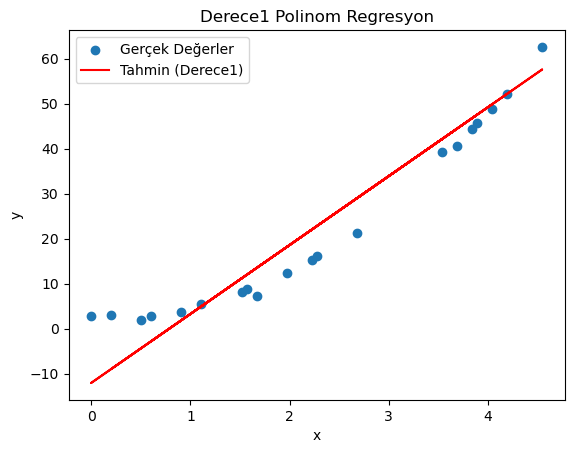

Degree=2.00, MSE=0.86, MAE=0.78, RMSE=0.93, R2=1.00


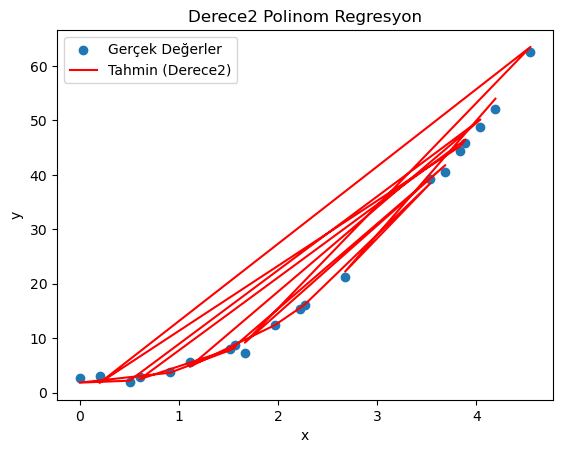

Degree=3.00, MSE=0.86, MAE=0.78, RMSE=0.93, R2=1.00


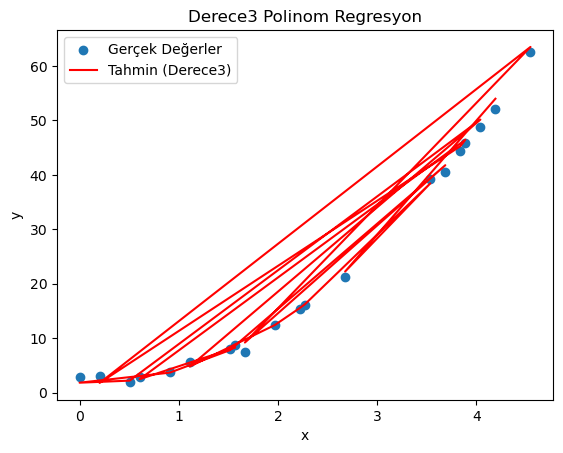

Degree=4.00, MSE=0.94, MAE=0.79, RMSE=0.97, R2=1.00


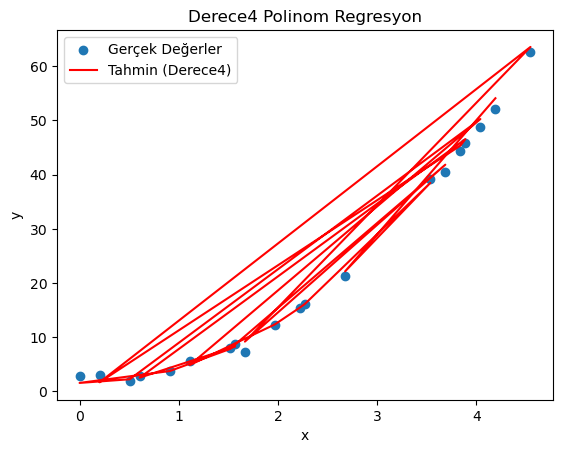

In [14]:
for degree in range(1,5):
    #polinom özellikleri oluşturma
    poly_features = PolynomialFeatures(degree=degree)
    X_poly_train=poly_features.fit_transform(X_train)
    X_poly_test = poly_features.transform(X_test)

    #model oluşturma ve eğitme
    model = LinearRegression()
    model.fit(X_poly_train,y_train)

    #tahmin ve değerlendirme
    y_pred=model.predict(X_poly_test)
    mse = mean_squared_error(y_test,y_pred)
    mae = mean_absolute_error(y_test,y_pred)
    rmse = math.sqrt(mse)
    r2 = r2_score(y_test,y_pred)

    print(f"Degree={degree:.2f}, MSE={mse:.2f}, MAE={mae:.2f}, RMSE={rmse:.2f}, R2={r2:.2f}")

    #görselleştirme
    plt.figure()
    plt.scatter(X_test,y_test,label="Gerçek Değerler")
    plt.plot(X_test,y_pred,color="red", label=f"Tahmin (Derece{degree})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.title(f"Derece{degree} Polinom Regresyon")
    plt.show()

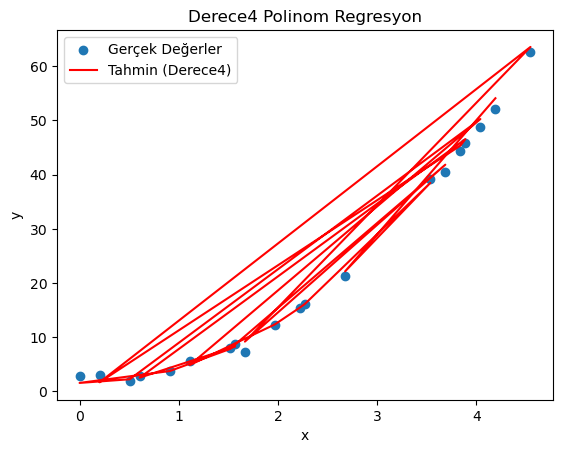